In [1]:
# Core data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

# Dataset (auto-downloads/loads from sklearn, no manual download needed)
from sklearn.datasets import load_breast_cancer

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler,
    LabelEncoder, OneHotEncoder, OrdinalEncoder
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Misc
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # fixed seed for reproducibility — always set this in professional ML work
print("All libraries imported successfully.")


All libraries imported successfully.


In [2]:
from sklearn.datasets import load_iris
iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [5]:
df=pd.DataFrame(iris.data,columns=iris.feature_names)
df['target']=iris.target
print ('shap=',df.shape)
df.head()

shap= (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [7]:
missing=df.isnull().sum()
print ('Total missing value =',missing.sum())

Total missing value = 0


In [8]:
print("Duplicate rows:", df.duplicated())

Duplicate rows: 0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


In [10]:
df['target'].unique()

array([0, 1, 2])

target
0    50
1    50
2    50
Name: count, dtype: int64


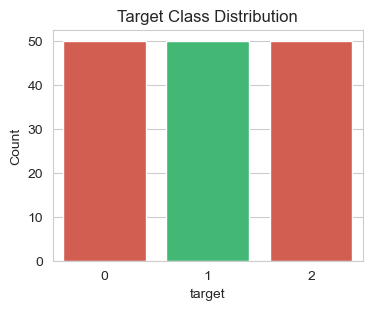


Class balance ratio: 1.00 : 1
Dataset is moderately imbalanced — stratified splitting will be used.


In [11]:
target_counts = df["target"].value_counts()
print(target_counts)

plt.figure(figsize=(4,3))
sns.countplot(x="target", data=df, palette=["#e74c3c", "#2ecc71"])
plt.xticks([0,1,2], [0, 1, 2])
plt.title("Target Class Distribution")
plt.ylabel("Count")
plt.show()

print(f"\nClass balance ratio: {target_counts[1]/target_counts[0]:.2f} : 1")
print("Dataset is moderately imbalanced — stratified splitting will be used.")


In [12]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


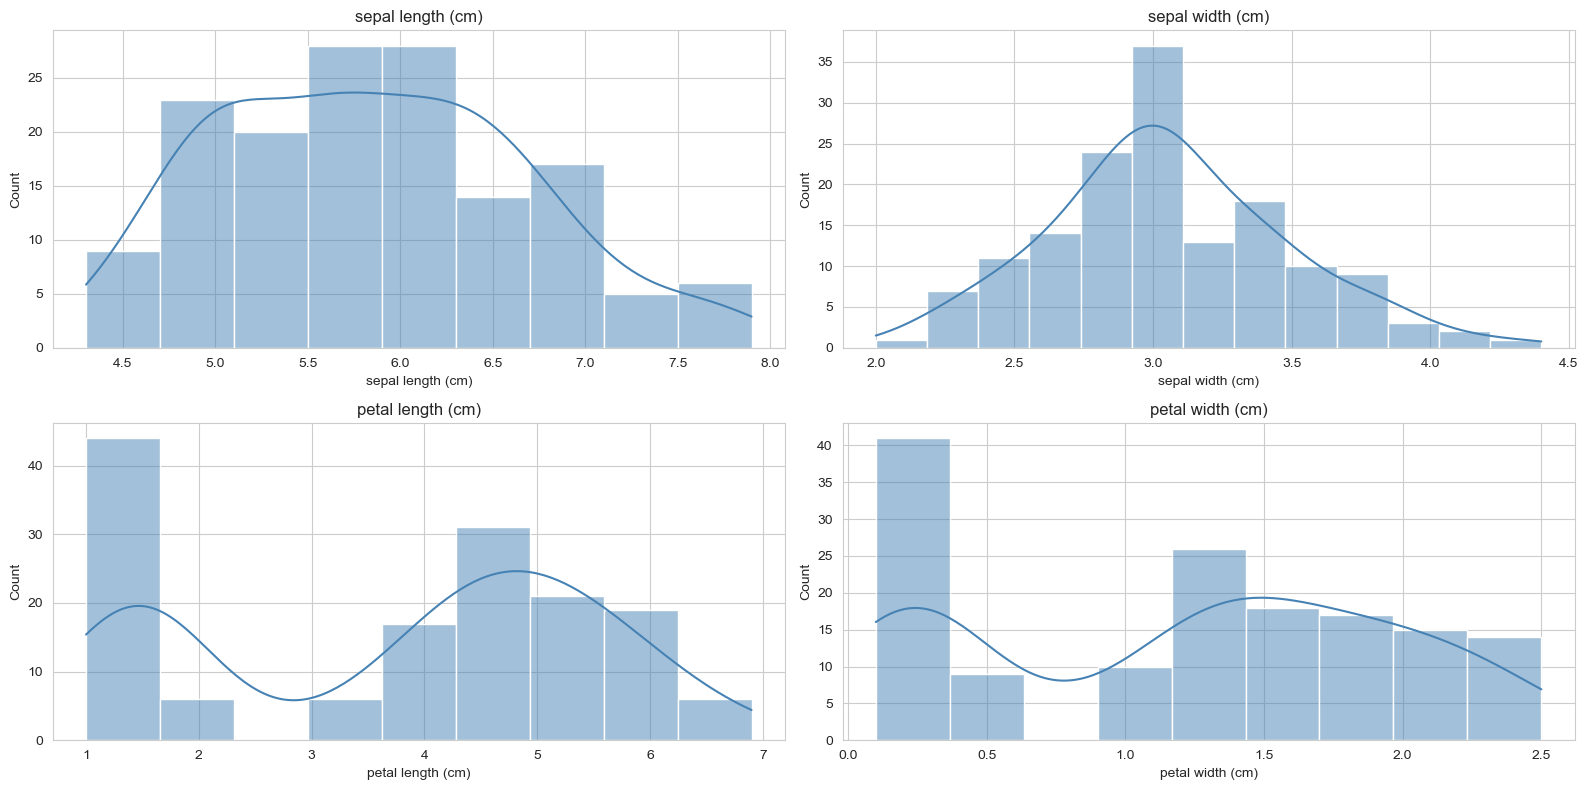

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
sample_features = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)",
                    "petal width (cm)"]

for ax, feature in zip(axes.flatten(), sample_features):
    sns.histplot(df[feature], kde=True, ax=ax, color="steelblue")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

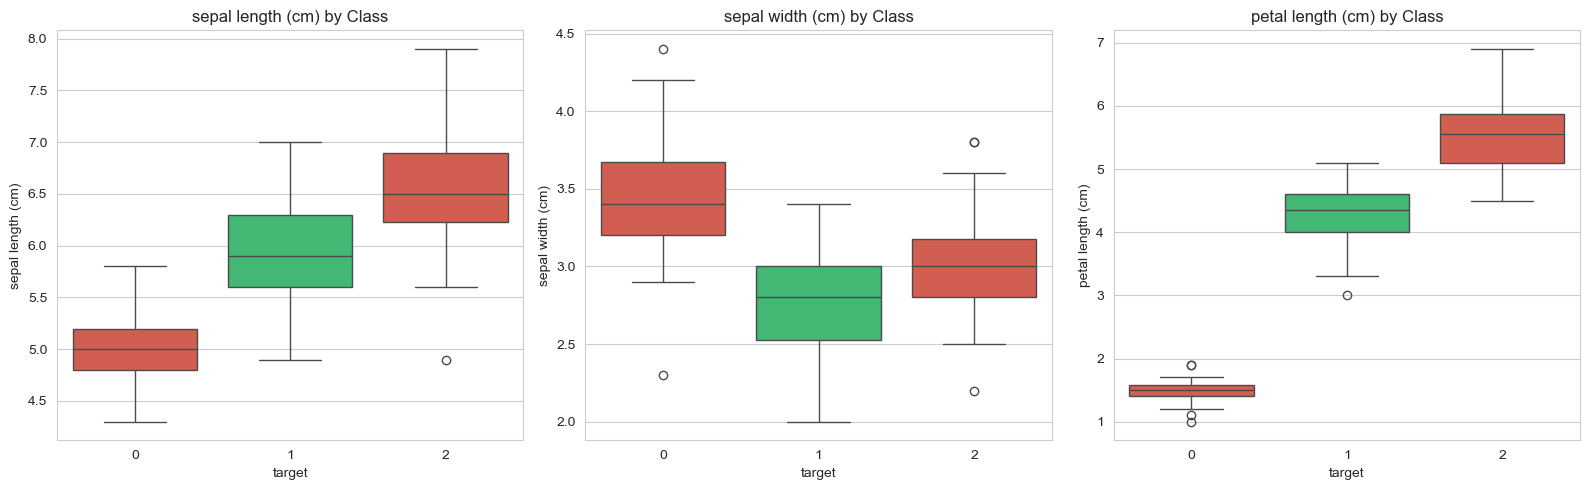

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feature in zip(axes, ["sepal length (cm)", "sepal width (cm)", "petal length (cm)",
                    "petal width (cm)"]):
    sns.boxplot(x="target", y=feature, data=df, ax=ax, palette=["#e74c3c", "#2ecc71"])
    ax.set_xticklabels([0, 1, 2])
    ax.set_title(f"{feature} by Class")

plt.tight_layout()
plt.show()

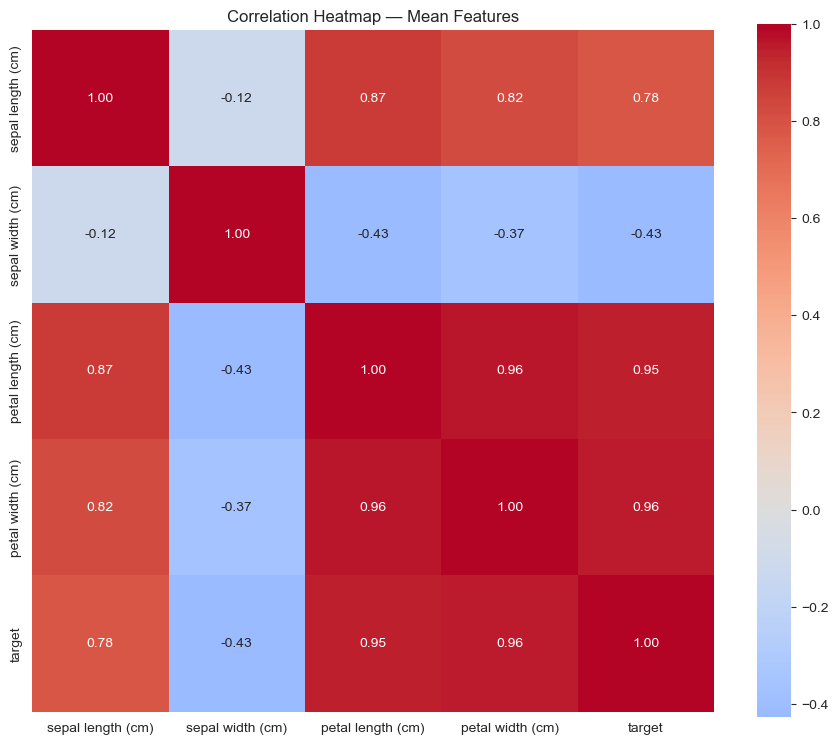

In [15]:
mean_features = [c for c in df.columns ]
corr = df[mean_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Mean Features")
plt.show()

In [16]:
def count_outliers_iqr(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return ((series < lower) | (series > upper)).sum()

outlier_summary = df.drop(columns=['target']).apply(count_outliers_iqr).sort_values(ascending=False)
print("Top features by outlier count:")
outlier_summary.head(100)

Top features by outlier count:


sepal width (cm)     4
sepal length (cm)    0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [17]:
X = df.drop(columns=['target'])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y          # preserves class balance in both sets
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))


Train shape: (120, 4)
Test shape: (30, 4)

Train class balance:
 target
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64

Test class balance:
 target
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64


In [18]:
minmax_scaler = MinMaxScaler()

# Fit ONLY on training data
X_train_norm = minmax_scaler.fit_transform(X_train)

# Transform test data using parameters learned from training data
X_test_norm = minmax_scaler.transform(X_test)

X_train_norm_df = pd.DataFrame(X_train_norm, columns=X_train.columns)
print("Before normalization (train):")
print(X_train.describe().loc[["min","max"]]. T.head())
print("\nAfter normalization (train) — all values now in [0, 1]:")
print(X_train_norm_df.describe().loc[["min","max"]].T.head())


Before normalization (train):
                   min  max
sepal length (cm)  4.3  7.9
sepal width (cm)   2.0  4.4
petal length (cm)  1.1  6.9
petal width (cm)   0.1  2.5

After normalization (train) — all values now in [0, 1]:
                   min  max
sepal length (cm)  0.0  1.0
sepal width (cm)   0.0  1.0
petal length (cm)  0.0  1.0
petal width (cm)   0.0  1.0


In [19]:
std_scaler = StandardScaler()

# Fit ONLY on training data — same leakage-prevention rule as before
X_train_scaled = std_scaler.fit_transform(X_train)
X_test_scaled = std_scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
print("After standardization (train) — mean ~0, std ~1:")
X_train_scaled_df.describe().loc[["mean","std"]].T.head()

After standardization (train) — mean ~0, std ~1:


,mean,std
sepal length (cm),-1.184238e-15,1.004193
sepal width (cm),-1.998401e-15,1.004193
petal length (cm),4.958996e-16,1.004193
petal width (cm),1.669035e-15,1.004193


In [20]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [21]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Quick demonstration: CV score of a baseline Logistic Regression on standardized data
baseline_model = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)

cv_scores = cross_val_score(
    baseline_model, X_train_scaled, y_train,
    cv=cv_strategy, scoring="accuracy"
)

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")


Fold accuracies: [0.9583 1.     0.9583 0.9583 0.9167]
Mean CV Accuracy: 0.9583  |  Std: 0.0264


In [22]:
results = []

for penalty, solver in [("l1", "liblinear"), ("l2", "liblinear")]:
    model = LogisticRegression(
        penalty=penalty, solver=solver, C=1.0,
        max_iter=10000, random_state=RANDOM_STATE
    )
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv_strategy, scoring="accuracy")
    results.append({"Penalty": penalty.upper(), "Mean CV Accuracy": scores.mean(), "Std": scores.std()})

reg_results_df = pd.DataFrame(results)
reg_results_df


,Penalty,Mean CV Accuracy,Std
0,L1,0.925000,0.031180
1,L2,0.883333,0.048591


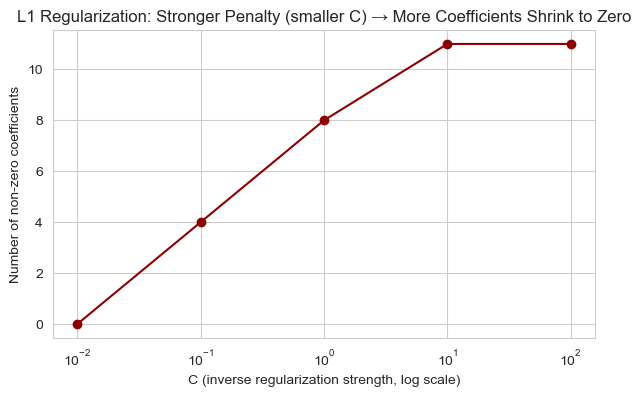

In [23]:
# Demonstrate effect of regularization STRENGTH (C) on number of zeroed-out coefficients (L1)
C_values = [0.01, 0.1, 1, 10, 100]
nonzero_counts = []

for C in C_values:
    model = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    nonzero_counts.append(np.sum(model.coef_ !=0.00))

plt.figure(figsize=(7,4))
plt.plot(C_values, nonzero_counts, marker="o", color="darkred")
plt.xscale("log")
plt.xlabel("C (inverse regularization strength, log scale)")
plt.ylabel("Number of non-zero coefficients")
plt.title("L1 Regularization: Stronger Penalty (smaller C) → More Coefficients Shrink to Zero")
plt.show()


In [24]:
models  = {
    "Logistic Regression": LogisticRegression(penalty="l2", C=1.0, max_iter=10000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    models[name] = model
    print(f"{name} trained successfully.")



Logistic Regression trained successfully.
Random Forest trained successfully.
SVM (RBF Kernel) trained successfully.


In [25]:
eval_results = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)
    
    eval_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1-Score": f1_score(y_test, y_pred, average='weighted'),
        "ROC-AUC": roc_auc_score(y_test, y_proba, multi_class='ovr')
    })

eval_df = pd.DataFrame(eval_results).set_index("Model").round(4)
eval_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9967
Random Forest,0.9000,0.9024,0.9000,0.8997,0.9933
SVM (RBF Kernel),0.9667,0.9697,0.9667,0.9666,0.9967


In [26]:
X_reg = df.drop(columns=['sepal length (cm)', 'target'], errors='ignore')
y_reg = df['sepal length (cm)']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

reg_scaler = StandardScaler()
X_train_reg_scaled = reg_scaler.fit_transform(X_train_reg)
X_test_reg_scaled = reg_scaler.transform(X_test_reg)


reg_model = LinearRegression()
reg_model.fit(X_train_reg_scaled, y_train_reg)

print("✅ Linear Regression Model train succseefullay")

✅ Linear Regression Model train succseefullay


=== Linear Regression Evaluation ===
R2 Score: 0.8520
Mean Squared Error (MSE): 0.1021
Mean Absolute Error (MAE): 0.2341


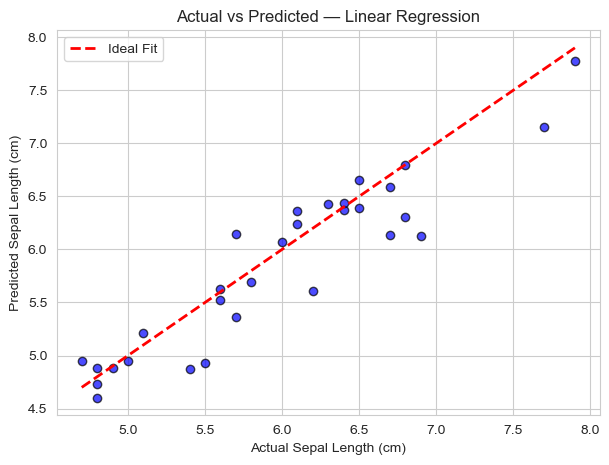

In [27]:
# 1. Predictions
y_pred_reg = reg_model.predict(X_test_reg_scaled)

# 2. Metrics Calculation
r2 = r2_score(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
mae = mean_absolute_error(y_test_reg, y_pred_reg)

print("=== Linear Regression Evaluation ===")
print(f"R2 Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# 3. Actual vs Predicted Graph (Regression Plot)
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, y_pred_reg, color='blue', alpha=0.7, edgecolors='k')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2, label="Ideal Fit")
plt.xlabel("Actual Sepal Length (cm)")
plt.ylabel("Predicted Sepal Length (cm)")
plt.title("Actual vs Predicted — Linear Regression")
plt.legend()
plt.show()

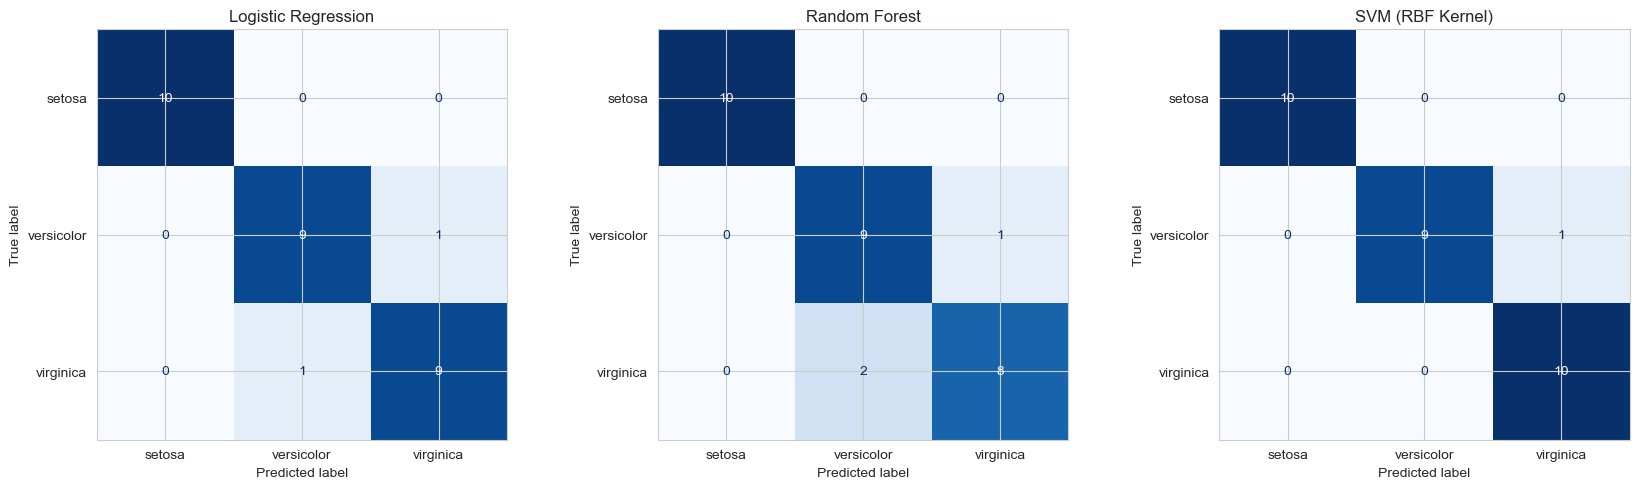

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

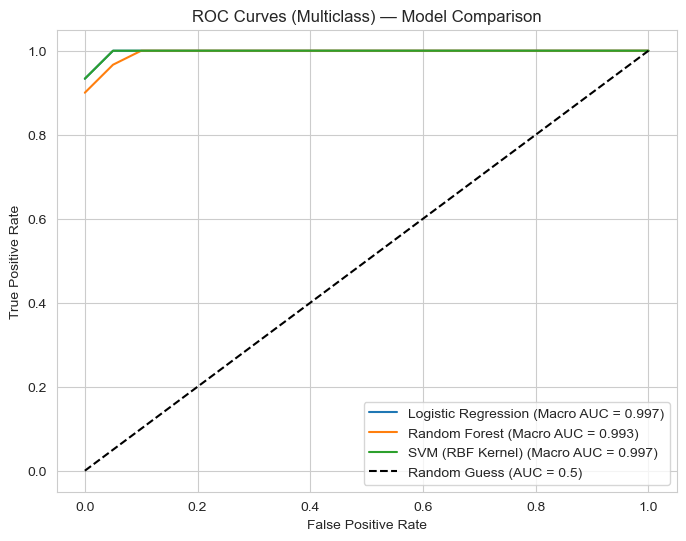

In [29]:
from sklearn.preprocessing import label_binarize
import numpy as np

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)
    fpr = dict()
    tpr = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    
    auc = roc_auc_score(y_test_bin, y_proba, multi_class='ovr', average='macro')
    plt.plot(all_fpr, mean_tpr, label=f"{name} (Macro AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Multiclass) — Model Comparison")
plt.legend()
plt.show()

In [30]:
best_model_name = eval_df["F1-Score"].idxmax()
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"Best model by F1-Score: {best_model_name}\n")
print(classification_report(y_test, y_pred_best, target_names=["Zero","Malignant", "Benign"]))

Best model by F1-Score: SVM (RBF Kernel)

              precision    recall  f1-score   support

        Zero       1.00      1.00      1.00        10
   Malignant       1.00      0.90      0.95        10
      Benign       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [31]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

# scoring ko "f1_weighted" ko day
grid_search = GridSearchCV(
    LogisticRegression(max_iter=10000, random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

Best parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV F1-Score: 0.9580


In [32]:
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test_scaled)
y_proba_final = final_model.predict_proba(X_test_scaled)
print("=== Final Model — Test Set Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_final, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_final, average='weighted'):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_final, multi_class='ovr', average='weighted'):.4f}")

=== Final Model — Test Set Performance ===
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333
ROC-AUC:   0.9933


# Schma

In [33]:
def build_numeric_schema(df, sep_decimal=2):
    schema = []
    numerical_columns = list(df._get_numeric_data().columns)
    for feat in numerical_columns:
        col = df[feat]
        step = abs(round((col.max() - col.min()) / 100, sep_decimal))
        if step == 0:
            step = 0.01

        schema.append({
            "name": feat,
            "dtype": "numeric",
            "min": float(col.min()),
            "max": float(col.max()),
            "mean": float(col.mean()),
            "step": float(step)
        })
    return schema

folder = "MODEL_FILES"

# 1. Classification Model & Schema
clf_schma = {
    "task_type": "classification",
    "model_name": best_model_name,
    "target_name": "target",
    "class_names": ["Setosa", "Versicolor", "Virginica"],
    "features": build_numeric_schema(X_train)
}
joblib.dump(best_model, f'{folder}/classification_model.pkl')
joblib.dump(std_scaler, f'{folder}/classification_scaler.pkl')
with open(f'{folder}/classification_schema.json', 'w') as f:
    json.dump(clf_schma, f, indent=2)

# 2. Regression Model & Schema
# (اگر آپ کے پاس ریگریشن کا الگ ماڈل reg_model ہے):
# 2. Correct Regression Model & Schema
Reg_schema = {
    "task_type": "regression",
    "model_name": "Linear Regression",
    "target_name": "sepal length (cm)",
    "features": build_numeric_schema(X_train_reg), 
    "requires_scaling": True
}

joblib.dump(reg_model, f'{folder}/regression_model.pkl')
joblib.dump(reg_scaler, f'{folder}/regression_scaler.pkl')  
with open(f'{folder}/regression_schema.json', 'w') as f:
    json.dump(Reg_schema, f, indent=2)

# Streamlit App

In [34]:
%%writefile streamlit_app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import os
import matplotlib.pyplot as plt

st.set_page_config(page_title="Dynamic ML Predictor", layout="centered")

ARTIFACT_DIR = "MODEL_FILES"

st.title("Dynamic Placement & Salary Predictor")
st.caption("This app builds inputs dynamically based on saved JSON schemas.")

# ---------------------------------------------------------
# 1. Discover available model bundles
# ---------------------------------------------------------
if not os.path.exists(ARTIFACT_DIR):
    st.error(f"Directory '{ARTIFACT_DIR}' not found. Please train models first.")
    st.stop()

available = [f.replace('_schema.json', '') for f in os.listdir(ARTIFACT_DIR) if f.endswith('_schema.json')]

if not available:
    st.error("No model schemas found. Run the training notebook first.")
    st.stop()

choice = st.selectbox("Choose a model to use:", available, format_func=lambda x: x.replace('_', ' ').title())

# ---------------------------------------------------------
# 2. Load chosen model + optional scaler + schema
# ---------------------------------------------------------
@st.cache_resource
def load_bundle(name):
    model = joblib.load(f"{ARTIFACT_DIR}/{name}_model.pkl")
    scaler_path = f"{ARTIFACT_DIR}/{name}_scaler.pkl"
    scaler = joblib.load(scaler_path) if os.path.exists(scaler_path) else None
    
    with open(f"{ARTIFACT_DIR}/{name}_schema.json") as f:
        schema = json.load(f)
        
    return model, scaler, schema

model, scaler, schema = load_bundle(choice)

st.subheader(f"Task: {schema['task_type'].title()}  |  Model: {schema['model_name']}")

# ---------------------------------------------------------
# 3. Dynamically build input form from schema
# ---------------------------------------------------------
st.markdown("### Enter Feature Values")
user_inputs = {}

with st.form("prediction_form"):
    cols = st.columns(2)
    for i, feat in enumerate(schema['features']):
        target_col = cols[i % 2]
        if feat['dtype'] == 'numeric':
            user_inputs[feat['name']] = target_col.slider(
                feat['name'],
                min_value=float(feat['min']),
                max_value=float(feat['max']),
                value=float(feat['mean']),
                step=float(feat['step'])
            )
        elif feat['dtype'] == 'categorical':
            user_inputs[feat['name']] = target_col.selectbox(feat['name'], feat['options'])
        else:
            user_inputs[feat['name']] = target_col.number_input(feat['name'], value=0.0)

    submitted = st.form_submit_button("Predict")

# ---------------------------------------------------------
# 4. Predict + Display Results
# ---------------------------------------------------------
if submitted:
    feature_order = [f['name'] for f in schema['features']]
    input_df = pd.DataFrame([[user_inputs[f] for f in feature_order]], columns=feature_order)

    if scaler is not None:
        input_data = scaler.transform(input_df)
    else:
        input_data = input_df

    if schema['task_type'] == 'regression':
        prediction = model.predict(input_data)[0]
        st.success(f"Predicted {schema['target_name']}: **{prediction:.2f} LPA**")

    elif schema['task_type'] == 'classification':
        prediction = model.predict(input_data)[0]
        class_names = schema.get('class_names', [str(prediction)])
        
        if isinstance(prediction, (int, np.integer)):
            pred_label = class_names[int(prediction)]
        else:
            pred_label = str(prediction)

        st.success(f"Predicted {schema['target_name']}: **{pred_label}**")

        if hasattr(model, "predict_proba"):
            proba = model.predict_proba(input_data)[0]
            
            # Matplotlib Plot (DLL Blocker کا سامنا نہیں کرے گا)
            fig, ax = plt.subplots(figsize=(5, 3))
            ax.bar(class_names, proba, color=['#ff9999', '#66b3ff'])
            ax.set_ylabel("Probability")
            ax.set_ylim(0, 1)
            ax.set_title("Prediction Probabilities")
            
            st.pyplot(fig)

Overwriting streamlit_app.py
